# 19 · Set 5f: do signals from different families add up? Cross-family ensembles (CPU, about 10–15 minutes)

**The question:** earlier steps combined signals only within one family. Signals from different families overlap little, so combining
them might give more than any one of them. This notebook tests that properly. **No model is run and no GPU is needed.**

| Group | Signal families |
|---|---|
| The question (free) | hand-made facts, words (TF-IDF), topics (topic model, 6 and 12 topics), similarity to the passages, sentence embedding |
| The retriever's first pass (free once it has run) | facts about the first try, hidden state at two layers |
| One cheap Llama 8B answer | hidden state at three places and two layers, evidence-use attention, token probabilities, stated confidence |

Each family is read three ways (linear, boosted trees, nearest neighbours). The resulting base models are combined 13 ways: plain and
group-balanced averages, averages of one group only, greedy selection of models that add to each other, stacking (logistic regression,
with class weighting, with SMOTE, boosted trees), and all features in one model.

Two decisions: keep the Llama 8B answer or ask the Qwen 32B (answerer); stop after one retrieval try or try twice more (retriever).

Three evaluations, so that no single sample decides: **old → fresh**, **fresh → old**, and **all 400 questions cross-validated** with the
whole pipeline refitted inside every fold.

**Named beforehand:** the primary ensemble is the average of every base model that separates better than chance on the training
questions. It "adds value" only if it beats the best single base model in the 400-question evaluation with a 95% interval that excludes
zero and is ahead in both transfer directions. Its gate must likewise beat a random gate.

Output: `runs/Set_2__question-reading-routers/<timestamp>_cpu_ensembles/results/` with `summary.md`, `set5f_ensembles.xlsx`, `verdict.json`, and charts.

**Runtime → Change runtime type → CPU.**

In [1]:
# ==== settings ====
PROJECT_DIR = "/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching"
EXPERIMENT  = "Set_2__question-reading-routers"
OLD_SWEEP_EXPERIMENT = "Set_1__3-modality-size"
FRESH_DATA  = f"{PROJECT_DIR}/data/hotpotqa_q/fresh200_c20_s43"
USE_EMBEDDING = True      # also use a small sentence-embedding model for the question and passages (downloads ~90 MB once)
CV_REPEATS = 2            # repeats of the 5-fold cross-validation over all 400 questions

EXPECTED_CODE = {
 "ssw.py": "c9fbdc7f6b91c58b607021b8be8c03ae2ff67dc1024fd2e24fffeb18e239ed98",
 "sweep.py": "9382292c6fe396cf79c73b212aaf6c2d677cae7f9311c3a5304f0578b52e6bb6",
 "routers.py": "8a293df1c8955716950f535cf9a3ced24439e00250173da1a3df110c0ed87304",
 "hidden.py": "574e6c1390e47c6de833a0c10b32c24eed0dee73a35eabc17f58842835e7f105",
 "final.py": "f18a6fba3d1bdd1f6700f6dc535f10ec0c41dbf5192b7b39ad097f8a1b88be53",
 "retriever_check.py": "fde08c549ecbd6bfc5527a42c731aa51dcff687a64818d68cf9cb30090e017e3",
 "ensemble.py": "5c5e87175d2484d806fda913a9555f71378a6031f050c37e89c20305942b76fc"
}

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
import glob, hashlib, json, os, shutil, subprocess, sys, time
from datetime import datetime
from zoneinfo import ZoneInfo
T_START = time.time()
def sha(p):
    return hashlib.sha256(open(p, "rb").read()).hexdigest()
CODE_DIR = "/content/set5code"
os.makedirs(CODE_DIR, exist_ok=True)
stale = []
for f, want in EXPECTED_CODE.items():
    shutil.copy(f"{PROJECT_DIR}/code/{f}", f"{CODE_DIR}/{f}")
    if sha(f"{CODE_DIR}/{f}") != want:
        stale.append(f)
assert not stale, (f"Drive is serving a different version of {stale} than this notebook was made for. Wait two minutes, then "
                   "Runtime -> Disconnect and delete runtime, and run again.")
sweeps = [d for d in sorted(glob.glob(f"{PROJECT_DIR}/runs/{OLD_SWEEP_EXPERIMENT}/*")) if "_dryrun" not in d and os.path.exists(f"{d}/results/per_question.jsonl")
          and os.path.exists(f"{d}/sweep_status.json") and json.load(open(f"{d}/sweep_status.json")).get("complete")]
hidden = [d for d in sorted(glob.glob(f"{PROJECT_DIR}/runs/{EXPERIMENT}/*_hidden")) if os.path.exists(f"{d}/step/hidden_retrieve_q7.jsonl")
          and os.path.exists(f"{d}/step/hidden_answer_l8.jsonl")]
fresh = [d for d in sorted(glob.glob(f"{PROJECT_DIR}/runs/{EXPERIMENT}/*_final")) if os.path.exists(f"{d}/step/hidden_retrieve_q7.jsonl")
         and os.path.exists(f"{d}/step/hidden_answer_l8.jsonl")]
assert sweeps and hidden and fresh, "Needs the finished runs of notebooks 11, 16, 17 and 18."
OLD_SWEEP, OLD_HIDDEN, FRESH_RUN = sweeps[-1], hidden[-1], fresh[-1]
OLD_DATA = json.load(open(f"{OLD_SWEEP}/config.json"))["data_dir"]
SESSION = datetime.now(ZoneInfo("Asia/Singapore")).strftime("%Y%m%d-%H%M%S")
RUN_DIR = f"{PROJECT_DIR}/runs/{EXPERIMENT}/{SESSION}_cpu_ensembles"
for d in (f"{RUN_DIR}/code", f"{RUN_DIR}/logs"):
    os.makedirs(d, exist_ok=True)
for f in EXPECTED_CODE:
    shutil.copy(f"{CODE_DIR}/{f}", f"{RUN_DIR}/code/{f}")
json.dump({"experiment": EXPERIMENT, "set": "5f cross-family ensembles", "old_sweep": OLD_SWEEP, "old_hidden": OLD_HIDDEN, "fresh_run": FRESH_RUN,
           "old_data": OLD_DATA, "fresh_data": FRESH_DATA, "use_embedding": USE_EMBEDDING, "cv_repeats": CV_REPEATS, "code": EXPECTED_CODE, "started": SESSION},
          open(f"{RUN_DIR}/config.json", "w"), indent=1)
print("Code files: current.")
print("Old questions:  ", OLD_SWEEP, "\n                ", OLD_HIDDEN)
print("Fresh questions:", FRESH_RUN)
print("Run folder:     ", RUN_DIR)

Code files: current.
Old questions:   /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_1__3-modality-size/20261004-165402_A100 
                 /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261007-075955_A100_hidden
Fresh questions: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261007-162319_A100_final
Run folder:      /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261007-233327_cpu_ensembles


In [4]:
# optional packages: without them the notebook still runs (no embedding families, no SMOTE row)
import importlib.util
if USE_EMBEDDING and importlib.util.find_spec("sentence_transformers") is None:
    print("installing sentence-transformers ...")
    !pip install -q sentence-transformers
if importlib.util.find_spec("imblearn") is None:
    print("installing imbalanced-learn ...")
    !pip install -q imbalanced-learn

### Run the study (about 10–15 minutes)

[15:33:30] ensemble code version 5f.3

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7505.57it/s]
[15:44:36] 400 questions (200 old, 200 fresh); question embedding: all-MiniLM-L6-v2
[15:45:06]   answerer | old -> fresh | fold 1/1 done
[15:45:49]   answerer | fresh -> old | fold 1/1 done
[15:46:37]   answerer | all 400, cross-validated | fold 1/10 done
[15:47:14]   answerer | all 400, cross-validated | fold 2/10 done
[15:47:47]   answerer | all 400, cross-validated | fold 3/10 done
[15:48:20]   answerer | all 400, cross-validated | fold 4/10 done
[15:48:58]   answerer | all 400, cross-validated | fold 5/10 done
[15:49:31]   answerer | all 400, cross-validated | fold 6/10 done
[15:50:04]   answerer | all 400, cross-validated | fold 7/10 done
[15:50:38]   answerer | all 400, cross-validated | fold 8/10 done
[15:51:14]   answerer | all 400, cross-validated | fold 9/10 done
[15:51:47]   answerer | all 400, cross-validated | fold 10/10 done
[15:53:34]   retriever | old -> fresh | f

# Set 5f - do signals from different families add up? Cross-family ensembles

Code version 5f.3. 400 questions (200 old, 200 fresh). No model was run; everything comes from notebooks 11, 16, 17 and 18. Question embedding: all-MiniLM-L6-v2.
Separation: 0.5 = useless, 1.0 = perfect. Every number is on questions that the models and thresholds did not see.

The fresh questions were already used to develop ideas in steps 5c to 5e, so none of this is an untouched test; the three evaluations guard against reading too much into one sample.

## Decision 1: after one Llama 8B answer, keep it or let the Qwen 32B answer?

**Does the primary ensemble add value over the best single base model?** Yes. **Does it beat one fixed hidden-state probe (the kind tested in notebooks 17 and 18)?** No. **Does its gate beat a random gate?** Yes. **Against the cheap fixed setup (all 400 questions):** -1.9 points of accuracy (95% interval -4.9 to +1.0) at -29% compute.

The 'best single base model' is picked among dozens on the training questions, which makes it a noisy and rather weak comparator; the fixed probe is the fairer one.

### Each signal family on its own (best reader of each family; mean over the three evaluations)

| Group | Signal family | old -> fresh | fresh -> old | all 400, cross-validated | Mean |
|---|---|---|---|---|---|
| one cheap Llama 8B answer | answerer: token probabilities | 0.63 | 0.72 | 0.67 | 0.67 |
| one cheap Llama 8B answer | answerer hidden state: final answer line (late layer) | 0.65 | 0.65 | 0.68 | 0.66 |
| one cheap Llama 8B answer | answerer hidden state: final answer line (middle layer) | 0.62 | 0.67 | 0.68 | 0.65 |
| one cheap Llama 8B answer | answerer: evidence-use attention | 0.69 | 0.60 | 0.66 | 0.65 |
| one cheap Llama 8B answer | answerer hidden state: all answer tokens (late layer) | 0.57 | 0.60 | 0.58 | 0.58 |
| one cheap Llama 8B answer | answerer hidden state: before answering (late layer) | 0.54 | 0.61 | 0.57 | 0.58 |
| one cheap Llama 8B answer | answerer hidden state: before answering (middle layer) | 0.56 | 0.57 | 0.58 | 0.57 |
| one cheap Llama 8B answer | answerer hidden state: all answer tokens (middle layer) | 0.51 | 0.56 | 0.55 | 0.54 |
| one cheap Llama 8B answer | answerer: stated confidence and lengths | 0.51 | 0.47 | 0.48 | 0.49 |
| the question (free, before anything runs) | question-passage similarity (words) | 0.54 | 0.57 | 0.58 | 0.56 |
| the question (free, before anything runs) | question facts | 0.55 | 0.57 | 0.54 | 0.55 |
| the question (free, before anything runs) | question-passage similarity (embedding) | 0.56 | 0.58 | 0.50 | 0.55 |
| the question (free, before anything runs) | question topics (topic model, 6 topics) | 0.46 | 0.61 | 0.53 | 0.53 |
| the question (free, before anything runs) | question topics (topic model, 12 topics) | 0.52 | 0.52 | 0.52 | 0.52 |
| the question (free, before anything runs) | question words (TF-IDF) | 0.55 | 0.47 | 0.52 | 0.51 |
| the question (free, before anything runs) | question embedding | 0.49 | 0.52 | 0.43 | 0.48 |
| the retriever's first pass (free once it has run) | retriever hidden state (last layer) | 0.57 | 0.57 | 0.61 | 0.58 |
| the retriever's first pass (free once it has run) | retriever hidden state (middle layer) | 0.58 | 0.55 | 0.59 | 0.57 |
| the retriever's first pass (free once it has run) | retriever: facts about its first try | 0.58 | 0.58 | 0.49 | 0.55 |

'Best reader' is picked per cell after the fact, so these single-family numbers are slightly flattered; the ensembles below are not.

### How much do the groups overlap? (correlation of their scores; low = they see different things)

| Between | Mean correlation of scores on the test questions |
|---|---|
| the question and the question | 0.10 |
| the question and the retriever's first pass | 0.03 |
| the retriever's first pass and the retriever's first pass | 0.18 |
| one cheap Llama 8B answer and the question | 0.02 |
| one cheap Llama 8B answer and the retriever's first pass | 0.06 |
| one cheap Llama 8B answer and one cheap Llama 8B answer | 0.21 |

### The ensembles

**all 400, cross-validated**

Separation, and whether the ensemble is ahead of a single model:

| Ensemble | Separation | 95% interval, low | 95% interval, high | Minus the best single base model | Difference: 95% interval, low | Difference: 95% interval, high | Minus the fixed probe | Minus the fixed probe: low | Minus the fixed probe: high |
|---|---|---|---|---|---|---|---|---|---|
| Reference: the best single base model on the training questions | 0.63 | 0.55 | 0.70 | +0.00 | +0.00 | +0.00 | -0.05 | -0.11 | +0.01 |
| Reference: one fixed hidden-state probe, as in notebooks 17 and 18 | 0.68 | 0.59 | 0.77 | +0.05 | -0.01 | +0.11 | +0.00 | +0.00 | +0.00 |
| PRIMARY: average of every base model above chance on the training questions | 0.69 | 0.62 | 0.77 | +0.06 | +0.01 | +0.12 | +0.01 | -0.04 | +0.07 |
| Stacked logistic regression over the base scores | 0.69 | 0.63 | 0.75 | +0.06 | -0.01 | +0.12 | +0.01 | -0.07 | +0.10 |
| Stacked logistic regression, classes weighted equally | 0.68 | 0.61 | 0.74 | +0.05 | -0.02 | +0.12 | -0.00 | -0.09 | +0.09 |
| Only one cheap Llama 8B answer: average of its base models | 0.67 | 0.59 | 0.75 | +0.04 | -0.03 | +0.10 | -0.02 | -0.08 | +0.06 |
| Stacked logistic regression with SMOTE | 0.67 | 0.60 | 0.72 | +0.03 | -0.04 | +0.11 | -0.02 | -0.10 | +0.08 |
| Greedy selection of base models that add to each other | 0.66 | 0.58 | 0.74 | +0.03 | -0.03 | +0.09 | -0.02 | -0.10 | +0.06 |
| Average of the linear reader of every family | 0.64 | 0.55 | 0.73 | +0.01 | -0.05 | +0.08 | -0.04 | -0.11 | +0.03 |
| Stacked boosted trees over the base scores | 0.64 | 0.57 | 0.71 | +0.01 | -0.06 | +0.08 | -0.04 | -0.12 | +0.04 |
| Average of all base models | 0.63 | 0.55 | 0.71 | -0.00 | -0.07 | +0.06 | -0.06 | -0.14 | +0.02 |
| Average with equal weight for each group (question, retriever, answerer) | 0.62 | 0.54 | 0.70 | -0.01 | -0.09 | +0.06 | -0.07 | -0.15 | +0.02 |
| All features of all families in one linear model | 0.61 | 0.53 | 0.69 | -0.02 | -0.09 | +0.04 | -0.08 | -0.15 | +0.00 |
| All features of all families in one boosted-tree model | 0.54 | 0.47 | 0.61 | -0.09 | -0.17 | -0.01 | -0.14 | -0.23 | -0.05 |
| Only the retriever's first pass: average of its base models | 0.54 | 0.46 | 0.61 | -0.10 | -0.19 | +0.01 | -0.15 | -0.25 | -0.04 |
| Only the question: average of its base models | 0.47 | 0.38 | 0.55 | -0.16 | -0.26 | -0.06 | -0.21 | -0.34 | -0.09 |

Used as a gate:

| Ensemble | Share acted on | Gate: accuracy | Random gate, same share: accuracy | Gate minus random: accuracy (points) | Gate minus random: accuracy, low | Gate minus random: accuracy, high | Gate accuracy minus the cheap fixed setup (points) | vs cheap fixed setup, low | vs cheap fixed setup, high | Gate compute vs the cheap fixed setup |
|---|---|---|---|---|---|---|---|---|---|---|
| Reference: the best single base model on the training questions | 40.8% | 56.6% | 54.2% | +2.4 | +0.82 | +4.1 | -1.9 | -4.6 | +0.75 | -24.9% |
| Reference: one fixed hidden-state probe, as in notebooks 17 and 18 | 37.4% | 56.1% | 54.0% | +2.2 | +0.01 | +4.2 | -2.4 | -5.1 | +0.38 | -27.1% |
| PRIMARY: average of every base model above chance on the training questions | 32.9% | 56.6% | 53.6% | +3.0 | +1.0 | +4.9 | -1.9 | -4.9 | +1.0 | -29.5% |
| Stacked logistic regression over the base scores | 37.4% | 57.1% | 54.0% | +3.2 | +1.5 | +4.9 | -1.4 | -4.1 | +1.4 | -27.6% |
| Stacked logistic regression, classes weighted equally | 38.6% | 57.4% | 54.1% | +3.3 | +1.7 | +5.0 | -1.1 | -3.9 | +1.5 | -27.0% |
| Only one cheap Llama 8B answer: average of its base models | 35.1% | 57.1% | 53.8% | +3.3 | +1.5 | +5.3 | -1.4 | -4.4 | +1.6 | -27.8% |
| Stacked logistic regression with SMOTE | 39.9% | 57.1% | 54.1% | +3.0 | +1.5 | +4.4 | -1.4 | -4.1 | +1.1 | -26.3% |
| Greedy selection of base models that add to each other | 35.0% | 57.0% | 53.8% | +3.2 | +1.5 | +5.0 | -1.5 | -4.5 | +1.4 | -28.4% |
| Average of the linear reader of every family | 34.2% | 55.8% | 53.7% | +2.0 | +0.21 | +3.9 | -2.7 | -6.0 | +0.25 | -28.1% |
| Stacked boosted trees over the base scores | 36.5% | 56.5% | 53.9% | +2.6 | +0.83 | +4.4 | -2.0 | -4.9 | +0.63 | -28.0% |
| Average of all base models | 34.1% | 55.6% | 53.7% | +1.9 | +0.14 | +3.9 | -2.9 | -6.1 | +0.00 | -28.4% |
| Average with equal weight for each group (question, retriever, answerer) | 33.4% | 56.1% | 53.7% | +2.5 | +0.65 | +4.3 | -2.4 | -5.6 | +0.38 | -29.0% |
| All features of all families in one linear model | 33.6% | 54.2% | 53.7% | +0.56 | -1.2 | +2.5 | -4.2 | -7.3 | -1.4 | -28.7% |
| All features of all families in one boosted-tree model | 36.8% | 54.0% | 53.9% | +0.09 | -1.5 | +1.8 | -4.5 | -7.4 | -1.8 | -27.6% |
| Only the retriever's first pass: average of its base models | 36.9% | 53.2% | 53.9% | -0.67 | -2.5 | +1.0 | -5.2 | -8.6 | -2.1 | -27.1% |
| Only the question: average of its base models | 34.2% | 53.4% | 53.7% | -0.36 | -2.2 | +1.2 | -5.1 | -8.5 | -2.2 | -29.4% |

**old -> fresh**

Separation, and whether the ensemble is ahead of a single model:

| Ensemble | Separation | 95% interval, low | 95% interval, high | Minus the best single base model | Difference: 95% interval, low | Difference: 95% interval, high | Minus the fixed probe | Minus the fixed probe: low | Minus the fixed probe: high |
|---|---|---|---|---|---|---|---|---|---|
| Reference: the best single base model on the training questions | 0.65 | 0.54 | 0.76 | +0.00 | +0.00 | +0.00 | +0.00 | +0.00 | +0.00 |
| Reference: one fixed hidden-state probe, as in notebooks 17 and 18 | 0.65 | 0.54 | 0.76 | +0.00 | +0.00 | +0.00 | +0.00 | +0.00 | +0.00 |
| PRIMARY: average of every base model above chance on the training questions | 0.67 | 0.55 | 0.77 | +0.01 | -0.07 | +0.09 | +0.01 | -0.07 | +0.09 |
| Greedy selection of base models that add to each other | 0.67 | 0.55 | 0.78 | +0.01 | -0.09 | +0.12 | +0.01 | -0.09 | +0.12 |
| Stacked logistic regression, classes weighted equally | 0.64 | 0.53 | 0.75 | -0.01 | -0.12 | +0.10 | -0.01 | -0.12 | +0.10 |
| Stacked logistic regression over the base scores | 0.63 | 0.52 | 0.74 | -0.02 | -0.12 | +0.08 | -0.02 | -0.12 | +0.08 |
| Average of the linear reader of every family | 0.63 | 0.51 | 0.74 | -0.03 | -0.16 | +0.11 | -0.03 | -0.16 | +0.11 |
| Stacked logistic regression with SMOTE | 0.63 | 0.51 | 0.74 | -0.03 | -0.15 | +0.10 | -0.03 | -0.15 | +0.10 |
| Stacked boosted trees over the base scores | 0.62 | 0.51 | 0.73 | -0.03 | -0.14 | +0.09 | -0.03 | -0.14 | +0.09 |
| Average with equal weight for each group (question, retriever, answerer) | 0.61 | 0.48 | 0.72 | -0.05 | -0.20 | +0.10 | -0.05 | -0.20 | +0.10 |
| Only one cheap Llama 8B answer: average of its base models | 0.60 | 0.48 | 0.72 | -0.05 | -0.17 | +0.06 | -0.05 | -0.17 | +0.06 |
| Average of all base models | 0.60 | 0.47 | 0.71 | -0.06 | -0.20 | +0.08 | -0.06 | -0.20 | +0.08 |
| Only the retriever's first pass: average of its base models | 0.59 | 0.47 | 0.70 | -0.07 | -0.24 | +0.11 | -0.07 | -0.24 | +0.11 |
| All features of all families in one linear model | 0.58 | 0.45 | 0.72 | -0.07 | -0.21 | +0.06 | -0.07 | -0.21 | +0.06 |
| All features of all families in one boosted-tree model | 0.57 | 0.43 | 0.71 | -0.08 | -0.21 | +0.06 | -0.08 | -0.21 | +0.06 |
| Only the question: average of its base models | 0.48 | 0.34 | 0.61 | -0.18 | -0.37 | +0.01 | -0.18 | -0.37 | +0.01 |

Used as a gate:

| Ensemble | Share acted on | Gate: accuracy | Random gate, same share: accuracy | Gate minus random: accuracy (points) | Gate minus random: accuracy, low | Gate minus random: accuracy, high | Gate accuracy minus the cheap fixed setup (points) | vs cheap fixed setup, low | vs cheap fixed setup, high | Gate compute vs the cheap fixed setup |
|---|---|---|---|---|---|---|---|---|---|---|
| Reference: the best single base model on the training questions | 35.5% | 53.0% | 50.3% | +2.7 | -0.49 | +5.7 | -0.50 | -5.0 | +4.0 | -28.1% |
| Reference: one fixed hidden-state probe, as in notebooks 17 and 18 | 35.5% | 53.0% | 50.3% | +2.7 | -0.49 | +5.7 | -0.50 | -5.0 | +4.0 | -28.1% |
| PRIMARY: average of every base model above chance on the training questions | 36.5% | 50.5% | 50.3% | +0.18 | -3.1 | +3.6 | -3.0 | -7.5 | +1.5 | -27.4% |
| Greedy selection of base models that add to each other | 42.5% | 52.0% | 50.6% | +1.4 | -1.9 | +4.6 | -1.5 | -5.5 | +2.0 | -24.2% |
| Stacked logistic regression, classes weighted equally | 41.0% | 53.0% | 50.6% | +2.4 | -0.60 | +5.6 | -0.50 | -5.0 | +3.5 | -25.2% |
| Stacked logistic regression over the base scores | 34.5% | 51.5% | 50.2% | +1.3 | -1.8 | +4.2 | -2.0 | -7.0 | +3.0 | -28.8% |
| Average of the linear reader of every family | 36.0% | 52.5% | 50.3% | +2.2 | -1.1 | +5.7 | -1.0 | -5.5 | +3.0 | -27.1% |
| Stacked logistic regression with SMOTE | 37.5% | 53.0% | 50.4% | +2.6 | -0.41 | +5.9 | -0.50 | -5.0 | +4.0 | -27.2% |
| Stacked boosted trees over the base scores | 44.0% | 53.5% | 50.7% | +2.8 | -0.33 | +6.0 | +0.00 | -4.5 | +4.5 | -23.3% |
| Average with equal weight for each group (question, retriever, answerer) | 36.0% | 51.0% | 50.3% | +0.70 | -2.5 | +3.9 | -2.5 | -7.0 | +2.0 | -27.6% |
| Only one cheap Llama 8B answer: average of its base models | 39.0% | 52.0% | 50.5% | +1.5 | -1.6 | +4.7 | -1.5 | -6.0 | +3.0 | -25.0% |
| Average of all base models | 36.5% | 52.0% | 50.3% | +1.7 | -1.5 | +4.9 | -1.5 | -6.0 | +2.5 | -27.1% |
| Only the retriever's first pass: average of its base models | 36.5% | 52.0% | 50.3% | +1.7 | -1.6 | +5.1 | -1.5 | -6.0 | +2.5 | -28.2% |
| All features of all families in one linear model | 39.0% | 51.5% | 50.5% | +1.0 | -2.0 | +4.2 | -2.0 | -6.5 | +2.0 | -25.3% |
| All features of all families in one boosted-tree model | 41.0% | 53.5% | 50.6% | +2.9 | -0.28 | +6.1 | +0.00 | -5.0 | +4.5 | -24.9% |
| Only the question: average of its base models | 34.5% | 50.5% | 50.2% | +0.28 | -2.6 | +3.3 | -3.0 | -8.0 | +2.0 | -29.5% |

**fresh -> old**

Separation, and whether the ensemble is ahead of a single model:

| Ensemble | Separation | 95% interval, low | 95% interval, high | Minus the best single base model | Difference: 95% interval, low | Difference: 95% interval, high | Minus the fixed probe | Minus the fixed probe: low | Minus the fixed probe: high |
|---|---|---|---|---|---|---|---|---|---|
| Reference: the best single base model on the training questions | 0.60 | 0.48 | 0.71 | +0.00 | +0.00 | +0.00 | -0.05 | -0.16 | +0.05 |
| Reference: one fixed hidden-state probe, as in notebooks 17 and 18 | 0.65 | 0.52 | 0.78 | +0.05 | -0.05 | +0.16 | +0.00 | +0.00 | +0.00 |
| PRIMARY: average of every base model above chance on the training questions | 0.70 | 0.59 | 0.81 | +0.10 | -0.04 | +0.24 | +0.05 | -0.05 | +0.16 |
| Only one cheap Llama 8B answer: average of its base models | 0.67 | 0.54 | 0.79 | +0.07 | -0.06 | +0.19 | +0.02 | -0.08 | +0.11 |
| Stacked logistic regression, classes weighted equally | 0.67 | 0.55 | 0.77 | +0.07 | -0.09 | +0.20 | +0.02 | -0.14 | +0.17 |
| Stacked logistic regression with SMOTE | 0.66 | 0.55 | 0.77 | +0.06 | -0.09 | +0.20 | +0.01 | -0.15 | +0.17 |
| Stacked logistic regression over the base scores | 0.66 | 0.54 | 0.77 | +0.06 | -0.10 | +0.20 | +0.01 | -0.14 | +0.16 |
| All features of all families in one linear model | 0.65 | 0.54 | 0.77 | +0.06 | -0.07 | +0.17 | +0.00 | -0.08 | +0.09 |
| Average of the linear reader of every family | 0.65 | 0.53 | 0.78 | +0.05 | -0.07 | +0.17 | -0.00 | -0.10 | +0.09 |
| Average of all base models | 0.64 | 0.51 | 0.77 | +0.04 | -0.08 | +0.16 | -0.01 | -0.13 | +0.10 |
| Stacked boosted trees over the base scores | 0.64 | 0.52 | 0.74 | +0.04 | -0.10 | +0.17 | -0.01 | -0.19 | +0.14 |
| Greedy selection of base models that add to each other | 0.62 | 0.50 | 0.75 | +0.03 | -0.12 | +0.16 | -0.02 | -0.14 | +0.09 |
| Average with equal weight for each group (question, retriever, answerer) | 0.62 | 0.50 | 0.74 | +0.02 | -0.09 | +0.14 | -0.03 | -0.16 | +0.09 |
| All features of all families in one boosted-tree model | 0.62 | 0.49 | 0.76 | +0.02 | -0.11 | +0.14 | -0.03 | -0.20 | +0.12 |
| Only the retriever's first pass: average of its base models | 0.57 | 0.45 | 0.68 | -0.03 | -0.16 | +0.09 | -0.08 | -0.23 | +0.06 |
| Only the question: average of its base models | 0.52 | 0.40 | 0.64 | -0.08 | -0.23 | +0.07 | -0.13 | -0.30 | +0.02 |

Used as a gate:

| Ensemble | Share acted on | Gate: accuracy | Random gate, same share: accuracy | Gate minus random: accuracy (points) | Gate minus random: accuracy, low | Gate minus random: accuracy, high | Gate accuracy minus the cheap fixed setup (points) | vs cheap fixed setup, low | vs cheap fixed setup, high | Gate compute vs the cheap fixed setup |
|---|---|---|---|---|---|---|---|---|---|---|
| Reference: the best single base model on the training questions | 37.5% | 58.5% | 57.6% | +0.94 | -1.6 | +3.6 | -5.0 | -9.0 | -1.0 | -27.8% |
| Reference: one fixed hidden-state probe, as in notebooks 17 and 18 | 37.0% | 58.5% | 57.5% | +0.98 | -1.8 | +4.0 | -5.0 | -8.5 | -2.0 | -27.5% |
| PRIMARY: average of every base model above chance on the training questions | 26.5% | 58.5% | 56.5% | +2.0 | -0.57 | +4.7 | -5.0 | -9.5 | -1.0 | -33.8% |
| Only one cheap Llama 8B answer: average of its base models | 34.5% | 60.0% | 57.3% | +2.7 | +0.04 | +5.7 | -3.5 | -7.0 | -0.50 | -28.4% |
| Stacked logistic regression, classes weighted equally | 39.0% | 61.0% | 57.7% | +3.3 | +0.70 | +6.0 | -2.5 | -6.0 | +1.0 | -26.4% |
| Stacked logistic regression with SMOTE | 37.0% | 60.0% | 57.5% | +2.5 | -0.10 | +5.1 | -3.5 | -7.5 | +0.00 | -27.9% |
| Stacked logistic regression over the base scores | 41.0% | 61.0% | 57.9% | +3.1 | +0.60 | +5.7 | -2.5 | -6.5 | +1.0 | -25.2% |
| All features of all families in one linear model | 35.0% | 60.5% | 57.3% | +3.2 | +0.70 | +5.6 | -3.0 | -6.5 | +0.51 | -27.3% |
| Average of the linear reader of every family | 25.0% | 60.5% | 56.4% | +4.1 | +1.7 | +6.6 | -3.0 | -7.0 | +1.0 | -34.3% |
| Average of all base models | 24.5% | 59.0% | 56.3% | +2.7 | +0.15 | +5.4 | -4.5 | -8.5 | +0.00 | -34.9% |
| Stacked boosted trees over the base scores | 26.5% | 58.5% | 56.5% | +2.0 | -0.78 | +4.6 | -5.0 | -9.0 | -1.0 | -34.2% |
| Greedy selection of base models that add to each other | 22.0% | 57.5% | 56.1% | +1.4 | -0.92 | +4.0 | -6.0 | -10.5 | -1.5 | -36.3% |
| Average with equal weight for each group (question, retriever, answerer) | 28.5% | 60.0% | 56.7% | +3.3 | +0.85 | +6.0 | -3.5 | -7.5 | +0.50 | -32.4% |
| All features of all families in one boosted-tree model | 38.5% | 60.5% | 57.7% | +2.8 | +0.32 | +5.6 | -3.0 | -6.5 | +0.50 | -26.4% |
| Only the retriever's first pass: average of its base models | 33.5% | 58.0% | 57.2% | +0.82 | -1.7 | +3.4 | -5.5 | -9.5 | -1.0 | -29.4% |
| Only the question: average of its base models | 29.0% | 58.0% | 56.8% | +1.2 | -1.2 | +3.6 | -5.5 | -10.0 | -1.0 | -32.7% |

What they were built from (old -> fresh):

- Reference: the best single base model on the training questions: answerer hidden state: final answer line (late layer) | linear
- Reference: one fixed hidden-state probe, as in notebooks 17 and 18: answerer hidden state: final answer line (late layer) | linear (the kind of probe tested in notebooks 17 and 18)
- PRIMARY: average of every base model above chance on the training questions: 12 of 57 base models above 0.60; groups: Q 0, R 2, A 10
- Greedy selection of base models that add to each other: answerer hidden state: final answer line (late layer) | linear; retriever hidden state (last layer) | trees; answerer: evidence-use attention | neighbours; answerer: token probabilities | trees; answerer hidden state: final answer line (middle layer) | trees; retriever hidden state (last layer) | linear; question topics (topic model, 6 topics) | linear

## Decision 2: after one Qwen 7B retrieval try, stop or try twice more?

**Does the primary ensemble add value over the best single base model?** Yes. **Does it beat one fixed hidden-state probe (the kind tested in notebooks 17 and 18)?** No. **Does its gate beat a random gate?** Yes. **Against the cheap fixed setup (all 400 questions):** +0.5 points of accuracy (95% interval -0.6 to +1.6) at +3% compute.

The 'best single base model' is picked among dozens on the training questions, which makes it a noisy and rather weak comparator; the fixed probe is the fairer one.

### Each signal family on its own (best reader of each family; mean over the three evaluations)

| Group | Signal family | old -> fresh | fresh -> old | all 400, cross-validated | Mean |
|---|---|---|---|---|---|
| the question (free, before anything runs) | question facts | 0.60 | 0.63 | 0.64 | 0.63 |
| the question (free, before anything runs) | question-passage similarity (embedding) | 0.62 | 0.63 | 0.63 | 0.63 |
| the question (free, before anything runs) | question embedding | 0.60 | 0.61 | 0.57 | 0.59 |
| the question (free, before anything runs) | question topics (topic model, 6 topics) | 0.59 | 0.60 | 0.56 | 0.58 |
| the question (free, before anything runs) | question-passage similarity (words) | 0.59 | 0.54 | 0.56 | 0.56 |
| the question (free, before anything runs) | question topics (topic model, 12 topics) | 0.52 | 0.54 | 0.54 | 0.54 |
| the question (free, before anything runs) | question words (TF-IDF) | 0.49 | 0.55 | 0.52 | 0.52 |
| the retriever's first pass (free once it has run) | retriever: facts about its first try | 0.63 | 0.64 | 0.66 | 0.64 |
| the retriever's first pass (free once it has run) | retriever hidden state (middle layer) | 0.63 | 0.56 | 0.66 | 0.62 |
| the retriever's first pass (free once it has run) | retriever hidden state (last layer) | 0.61 | 0.59 | 0.61 | 0.61 |

'Best reader' is picked per cell after the fact, so these single-family numbers are slightly flattered; the ensembles below are not.

### How much do the groups overlap? (correlation of their scores; low = they see different things)

| Between | Mean correlation of scores on the test questions |
|---|---|
| the question and the question | 0.16 |
| the question and the retriever's first pass | 0.07 |
| the retriever's first pass and the retriever's first pass | 0.25 |

### The ensembles

**all 400, cross-validated**

Separation, and whether the ensemble is ahead of a single model:

| Ensemble | Separation | 95% interval, low | 95% interval, high | Minus the best single base model | Difference: 95% interval, low | Difference: 95% interval, high | Minus the fixed probe | Minus the fixed probe: low | Minus the fixed probe: high |
|---|---|---|---|---|---|---|---|---|---|
| Reference: the best single base model on the training questions | 0.61 | 0.55 | 0.66 | +0.00 | +0.00 | +0.00 | -0.05 | -0.09 | -0.00 |
| Reference: one fixed hidden-state probe, as in notebooks 17 and 18 | 0.66 | 0.59 | 0.72 | +0.05 | +0.00 | +0.09 | +0.00 | +0.00 | +0.00 |
| PRIMARY: average of every base model above chance on the training questions | 0.67 | 0.61 | 0.74 | +0.07 | +0.02 | +0.12 | +0.02 | -0.03 | +0.07 |
| Only the retriever's first pass: average of its base models | 0.70 | 0.64 | 0.76 | +0.09 | +0.03 | +0.14 | +0.04 | -0.01 | +0.09 |
| Greedy selection of base models that add to each other | 0.68 | 0.63 | 0.74 | +0.07 | +0.02 | +0.13 | +0.03 | -0.03 | +0.08 |
| Average with equal weight for each group (question, retriever, answerer) | 0.68 | 0.62 | 0.74 | +0.07 | +0.02 | +0.12 | +0.03 | -0.02 | +0.08 |
| Average of the linear reader of every family | 0.66 | 0.60 | 0.73 | +0.05 | -0.01 | +0.11 | +0.01 | -0.05 | +0.06 |
| Stacked logistic regression, classes weighted equally | 0.66 | 0.60 | 0.72 | +0.05 | -0.00 | +0.10 | +0.00 | -0.06 | +0.06 |
| Stacked logistic regression with SMOTE | 0.66 | 0.60 | 0.72 | +0.05 | -0.01 | +0.10 | +0.00 | -0.06 | +0.06 |
| Stacked logistic regression over the base scores | 0.66 | 0.60 | 0.72 | +0.05 | -0.01 | +0.10 | +0.00 | -0.06 | +0.06 |
| Average of all base models | 0.65 | 0.59 | 0.71 | +0.04 | -0.01 | +0.10 | -0.01 | -0.06 | +0.05 |
| All features of all families in one linear model | 0.65 | 0.58 | 0.72 | +0.04 | -0.03 | +0.10 | -0.01 | -0.08 | +0.05 |
| Stacked boosted trees over the base scores | 0.63 | 0.57 | 0.69 | +0.02 | -0.04 | +0.07 | -0.03 | -0.09 | +0.03 |
| All features of all families in one boosted-tree model | 0.59 | 0.53 | 0.66 | -0.02 | -0.08 | +0.05 | -0.06 | -0.13 | +0.01 |
| Only the question: average of its base models | 0.58 | 0.52 | 0.65 | -0.03 | -0.09 | +0.04 | -0.07 | -0.14 | -0.00 |

Used as a gate:

| Ensemble | Share acted on | Gate: both passages found | Random gate, same share: both passages found | Gate minus random: both passages found (points) | Gate minus random: both passages found, low | Gate minus random: both passages found, high | Gate accuracy minus the cheap fixed setup (points) | vs cheap fixed setup, low | vs cheap fixed setup, high | Gate compute vs the cheap fixed setup |
|---|---|---|---|---|---|---|---|---|---|---|
| Reference: the best single base model on the training questions | 19.4% | 82.6% | 81.6% | +0.99 | -0.18 | +2.3 | +0.38 | -0.75 | +1.5 | +2.7% |
| Reference: one fixed hidden-state probe, as in notebooks 17 and 18 | 17.5% | 82.8% | 81.4% | +1.3 | +0.12 | +2.7 | +0.38 | -0.88 | +1.6 | +2.5% |
| PRIMARY: average of every base model above chance on the training questions | 20.1% | 84.2% | 81.7% | +2.5 | +1.0 | +4.1 | +0.50 | -0.62 | +1.6 | +3.0% |
| Only the retriever's first pass: average of its base models | 17.4% | 84.4% | 81.4% | +3.0 | +1.5 | +4.7 | +0.63 | -0.75 | +2.0 | +2.8% |
| Greedy selection of base models that add to each other | 18.4% | 83.6% | 81.5% | +2.1 | +0.74 | +3.6 | +0.13 | -1.0 | +1.2 | +2.8% |
| Average with equal weight for each group (question, retriever, answerer) | 18.8% | 84.8% | 81.6% | +3.2 | +1.6 | +4.9 | +0.50 | -0.75 | +1.9 | +2.8% |
| Average of the linear reader of every family | 18.2% | 84.2% | 81.5% | +2.7 | +1.2 | +4.4 | +0.38 | -0.88 | +1.7 | +2.9% |
| Stacked logistic regression, classes weighted equally | 20.6% | 83.6% | 81.8% | +1.9 | +0.50 | +3.2 | +0.13 | -0.87 | +1.0 | +3.2% |
| Stacked logistic regression with SMOTE | 21.1% | 83.8% | 81.8% | +1.9 | +0.60 | +3.2 | -0.12 | -1.0 | +0.75 | +3.3% |
| Stacked logistic regression over the base scores | 21.8% | 83.8% | 81.9% | +1.9 | +0.35 | +3.4 | -0.12 | -1.1 | +1.0 | +3.4% |
| Average of all base models | 18.9% | 84.2% | 81.6% | +2.7 | +1.2 | +4.3 | +0.50 | -0.62 | +1.8 | +2.7% |
| All features of all families in one linear model | 19.6% | 83.9% | 81.7% | +2.2 | +0.77 | +3.8 | +0.63 | -0.38 | +1.7 | +3.2% |
| Stacked boosted trees over the base scores | 21.9% | 83.8% | 81.9% | +1.8 | +0.43 | +3.3 | +0.63 | -0.38 | +1.8 | +3.3% |
| All features of all families in one boosted-tree model | 20.4% | 82.9% | 81.7% | +1.1 | -0.05 | +2.5 | +0.75 | +0.00 | +1.6 | +2.8% |
| Only the question: average of its base models | 18.9% | 82.8% | 81.6% | +1.2 | -0.08 | +2.6 | +0.50 | -0.37 | +1.5 | +2.3% |

**old -> fresh**

Separation, and whether the ensemble is ahead of a single model:

| Ensemble | Separation | 95% interval, low | 95% interval, high | Minus the best single base model | Difference: 95% interval, low | Difference: 95% interval, high | Minus the fixed probe | Minus the fixed probe: low | Minus the fixed probe: high |
|---|---|---|---|---|---|---|---|---|---|
| Reference: the best single base model on the training questions | 0.63 | 0.54 | 0.72 | +0.00 | +0.00 | +0.00 | +0.00 | +0.00 | +0.00 |
| Reference: one fixed hidden-state probe, as in notebooks 17 and 18 | 0.63 | 0.54 | 0.72 | +0.00 | +0.00 | +0.00 | +0.00 | +0.00 | +0.00 |
| PRIMARY: average of every base model above chance on the training questions | 0.65 | 0.55 | 0.74 | +0.02 | -0.06 | +0.08 | +0.02 | -0.06 | +0.08 |
| Greedy selection of base models that add to each other | 0.67 | 0.59 | 0.75 | +0.04 | -0.03 | +0.11 | +0.04 | -0.03 | +0.11 |
| Stacked boosted trees over the base scores | 0.67 | 0.59 | 0.74 | +0.03 | -0.03 | +0.11 | +0.03 | -0.03 | +0.11 |
| Stacked logistic regression, classes weighted equally | 0.67 | 0.57 | 0.76 | +0.03 | -0.05 | +0.11 | +0.03 | -0.05 | +0.11 |
| Stacked logistic regression over the base scores | 0.67 | 0.57 | 0.75 | +0.03 | -0.05 | +0.11 | +0.03 | -0.05 | +0.11 |
| Only the retriever's first pass: average of its base models | 0.66 | 0.57 | 0.73 | +0.02 | -0.05 | +0.09 | +0.02 | -0.05 | +0.09 |
| Stacked logistic regression with SMOTE | 0.65 | 0.56 | 0.75 | +0.02 | -0.07 | +0.10 | +0.02 | -0.07 | +0.10 |
| Average with equal weight for each group (question, retriever, answerer) | 0.64 | 0.56 | 0.73 | +0.01 | -0.06 | +0.07 | +0.01 | -0.06 | +0.07 |
| Average of the linear reader of every family | 0.63 | 0.54 | 0.71 | -0.01 | -0.08 | +0.06 | -0.01 | -0.08 | +0.06 |
| Average of all base models | 0.63 | 0.53 | 0.71 | -0.01 | -0.08 | +0.06 | -0.01 | -0.08 | +0.06 |
| All features of all families in one linear model | 0.62 | 0.52 | 0.70 | -0.02 | -0.10 | +0.06 | -0.02 | -0.10 | +0.06 |
| Only the question: average of its base models | 0.59 | 0.49 | 0.67 | -0.05 | -0.14 | +0.04 | -0.05 | -0.14 | +0.04 |
| All features of all families in one boosted-tree model | 0.53 | 0.43 | 0.61 | -0.11 | -0.21 | -0.02 | -0.11 | -0.21 | -0.02 |

Used as a gate:

| Ensemble | Share acted on | Gate: both passages found | Random gate, same share: both passages found | Gate minus random: both passages found (points) | Gate minus random: both passages found, low | Gate minus random: both passages found, high | Gate accuracy minus the cheap fixed setup (points) | vs cheap fixed setup, low | vs cheap fixed setup, high | Gate compute vs the cheap fixed setup |
|---|---|---|---|---|---|---|---|---|---|---|
| Reference: the best single base model on the training questions | 15.0% | 78.5% | 77.2% | +1.3 | -0.56 | +3.3 | +0.50 | +0.00 | +1.5 | +2.4% |
| Reference: one fixed hidden-state probe, as in notebooks 17 and 18 | 15.0% | 78.5% | 77.2% | +1.3 | -0.56 | +3.3 | +0.50 | +0.00 | +1.5 | +2.4% |
| PRIMARY: average of every base model above chance on the training questions | 15.0% | 80.0% | 77.2% | +2.8 | +0.61 | +5.1 | +0.00 | -1.5 | +1.5 | +2.2% |
| Greedy selection of base models that add to each other | 11.0% | 78.0% | 76.8% | +1.2 | -0.40 | +3.1 | -0.50 | -1.5 | +0.00 | +1.8% |
| Stacked boosted trees over the base scores | 13.5% | 78.5% | 77.1% | +1.4 | -0.22 | +3.4 | +0.50 | -1.0 | +2.0 | +2.1% |
| Stacked logistic regression, classes weighted equally | 15.5% | 79.0% | 77.3% | +1.7 | -0.08 | +3.9 | +0.50 | -1.0 | +2.0 | +2.5% |
| Stacked logistic regression over the base scores | 15.5% | 79.0% | 77.3% | +1.7 | -0.06 | +3.9 | +0.50 | -1.0 | +2.0 | +2.5% |
| Only the retriever's first pass: average of its base models | 14.5% | 78.5% | 77.2% | +1.3 | -0.50 | +3.4 | +2.0 | -0.50 | +4.5 | +2.4% |
| Stacked logistic regression with SMOTE | 19.0% | 80.0% | 77.7% | +2.3 | +0.27 | +4.6 | +2.0 | +0.00 | +4.5 | +2.9% |
| Average with equal weight for each group (question, retriever, answerer) | 18.0% | 79.0% | 77.6% | +1.4 | -0.55 | +3.6 | +1.5 | -0.50 | +3.5 | +2.7% |
| Average of the linear reader of every family | 18.5% | 79.0% | 77.6% | +1.4 | -0.50 | +3.6 | +0.50 | -1.5 | +3.0 | +2.7% |
| Average of all base models | 17.5% | 78.5% | 77.5% | +0.99 | -0.87 | +3.0 | +0.50 | -1.0 | +2.5 | +2.6% |
| All features of all families in one linear model | 22.0% | 81.5% | 78.0% | +3.5 | +1.2 | +6.0 | +1.0 | -1.0 | +3.0 | +3.0% |
| Only the question: average of its base models | 17.5% | 78.0% | 77.5% | +0.49 | -1.2 | +2.4 | +0.00 | -1.5 | +1.5 | +2.2% |
| All features of all families in one boosted-tree model | 12.5% | 78.5% | 76.9% | +1.6 | -0.24 | +3.5 | +0.50 | +0.00 | +1.5 | +1.7% |

**fresh -> old**

Separation, and whether the ensemble is ahead of a single model:

| Ensemble | Separation | 95% interval, low | 95% interval, high | Minus the best single base model | Difference: 95% interval, low | Difference: 95% interval, high | Minus the fixed probe | Minus the fixed probe: low | Minus the fixed probe: high |
|---|---|---|---|---|---|---|---|---|---|
| Reference: the best single base model on the training questions | 0.53 | 0.42 | 0.63 | +0.00 | +0.00 | +0.00 | -0.03 | -0.11 | +0.04 |
| Reference: one fixed hidden-state probe, as in notebooks 17 and 18 | 0.56 | 0.45 | 0.66 | +0.03 | -0.04 | +0.11 | +0.00 | +0.00 | +0.00 |
| PRIMARY: average of every base model above chance on the training questions | 0.59 | 0.48 | 0.69 | +0.07 | -0.04 | +0.18 | +0.04 | -0.09 | +0.16 |
| All features of all families in one boosted-tree model | 0.68 | 0.58 | 0.77 | +0.16 | +0.04 | +0.27 | +0.13 | -0.00 | +0.25 |
| Average of the linear reader of every family | 0.66 | 0.57 | 0.74 | +0.13 | +0.03 | +0.23 | +0.10 | -0.01 | +0.21 |
| All features of all families in one linear model | 0.65 | 0.54 | 0.74 | +0.13 | +0.00 | +0.25 | +0.10 | -0.05 | +0.22 |
| Only the retriever's first pass: average of its base models | 0.64 | 0.55 | 0.74 | +0.12 | +0.03 | +0.22 | +0.09 | -0.01 | +0.19 |
| Average with equal weight for each group (question, retriever, answerer) | 0.63 | 0.54 | 0.73 | +0.11 | +0.02 | +0.20 | +0.08 | -0.03 | +0.18 |
| Average of all base models | 0.62 | 0.52 | 0.71 | +0.10 | -0.00 | +0.20 | +0.07 | -0.06 | +0.18 |
| Stacked boosted trees over the base scores | 0.59 | 0.48 | 0.69 | +0.06 | -0.07 | +0.20 | +0.03 | -0.11 | +0.16 |
| Greedy selection of base models that add to each other | 0.57 | 0.46 | 0.68 | +0.05 | -0.05 | +0.16 | +0.02 | -0.11 | +0.13 |
| Only the question: average of its base models | 0.57 | 0.46 | 0.66 | +0.04 | -0.09 | +0.17 | +0.01 | -0.13 | +0.15 |
| Stacked logistic regression with SMOTE | 0.56 | 0.45 | 0.69 | +0.04 | -0.10 | +0.19 | +0.01 | -0.13 | +0.15 |
| Stacked logistic regression over the base scores | 0.54 | 0.42 | 0.66 | +0.01 | -0.11 | +0.16 | -0.02 | -0.15 | +0.12 |
| Stacked logistic regression, classes weighted equally | 0.53 | 0.41 | 0.64 | +0.00 | -0.13 | +0.14 | -0.03 | -0.16 | +0.11 |

Used as a gate:

| Ensemble | Share acted on | Gate: both passages found | Random gate, same share: both passages found | Gate minus random: both passages found (points) | Gate minus random: both passages found, low | Gate minus random: both passages found, high | Gate accuracy minus the cheap fixed setup (points) | vs cheap fixed setup, low | vs cheap fixed setup, high | Gate compute vs the cheap fixed setup |
|---|---|---|---|---|---|---|---|---|---|---|
| Reference: the best single base model on the training questions | 18.0% | 86.0% | 85.4% | +0.61 | -1.1 | +2.5 | +1.0 | +0.00 | +2.5 | +2.5% |
| Reference: one fixed hidden-state probe, as in notebooks 17 and 18 | 16.5% | 86.0% | 85.2% | +0.77 | -0.86 | +2.5 | -0.50 | -2.5 | +1.0 | +2.7% |
| PRIMARY: average of every base model above chance on the training questions | 21.0% | 87.5% | 85.7% | +1.8 | -0.25 | +4.0 | -1.0 | -2.5 | +0.00 | +3.8% |
| All features of all families in one boosted-tree model | 18.0% | 86.5% | 85.4% | +1.1 | -0.70 | +3.2 | +1.5 | +0.00 | +3.5 | +3.1% |
| Average of the linear reader of every family | 20.5% | 86.5% | 85.7% | +0.85 | -0.90 | +2.8 | +0.50 | +0.00 | +1.5 | +3.1% |
| All features of all families in one linear model | 20.5% | 87.0% | 85.7% | +1.3 | -0.73 | +3.5 | +0.50 | +0.00 | +1.5 | +3.4% |
| Only the retriever's first pass: average of its base models | 21.0% | 88.0% | 85.7% | +2.3 | +0.34 | +4.5 | -0.50 | -3.0 | +1.5 | +3.2% |
| Average with equal weight for each group (question, retriever, answerer) | 16.5% | 87.0% | 85.2% | +1.8 | -0.10 | +3.8 | -0.50 | -1.5 | +0.00 | +2.3% |
| Average of all base models | 18.5% | 86.5% | 85.4% | +1.1 | -0.75 | +3.1 | +0.00 | +0.00 | +0.00 | +2.3% |
| Stacked boosted trees over the base scores | 22.0% | 88.0% | 85.8% | +2.2 | +0.09 | +4.4 | -1.0 | -3.5 | +1.0 | +3.3% |
| Greedy selection of base models that add to each other | 18.0% | 86.5% | 85.4% | +1.1 | -0.69 | +3.0 | -1.0 | -2.5 | +0.00 | +2.9% |
| Only the question: average of its base models | 19.5% | 86.0% | 85.5% | +0.45 | -1.2 | +2.4 | +0.50 | +0.00 | +1.5 | +2.5% |
| Stacked logistic regression with SMOTE | 20.0% | 87.5% | 85.6% | +1.9 | -0.19 | +4.3 | +0.00 | -2.5 | +2.5 | +3.1% |
| Stacked logistic regression over the base scores | 19.5% | 87.0% | 85.5% | +1.5 | -0.44 | +3.7 | +0.00 | -2.5 | +2.5 | +3.1% |
| Stacked logistic regression, classes weighted equally | 21.0% | 87.0% | 85.7% | +1.3 | -0.63 | +3.5 | +0.00 | -2.5 | +2.5 | +3.2% |

What they were built from (old -> fresh):

- Reference: the best single base model on the training questions: retriever hidden state (middle layer) | linear
- Reference: one fixed hidden-state probe, as in notebooks 17 and 18: retriever hidden state (middle layer) | linear (the kind of probe tested in notebooks 17 and 18)
- PRIMARY: average of every base model above chance on the training questions: 14 of 30 base models above 0.59; groups: Q 7, R 7
- Greedy selection of base models that add to each other: retriever hidden state (middle layer) | linear; retriever hidden state (last layer) | trees; question-passage similarity (embedding) | linear; retriever: facts about its first try | linear; question embedding | trees

## How to read the many rows

There are 81 ensemble-by-evaluation rows. At a 95% level about 4 of them would show an interval that excludes zero by chance alone, which is why only the primary ensemble, named beforehand, decides the answer.

Charts: `results/charts/`. Excel: `results/set5f_ensembles.xlsx`.


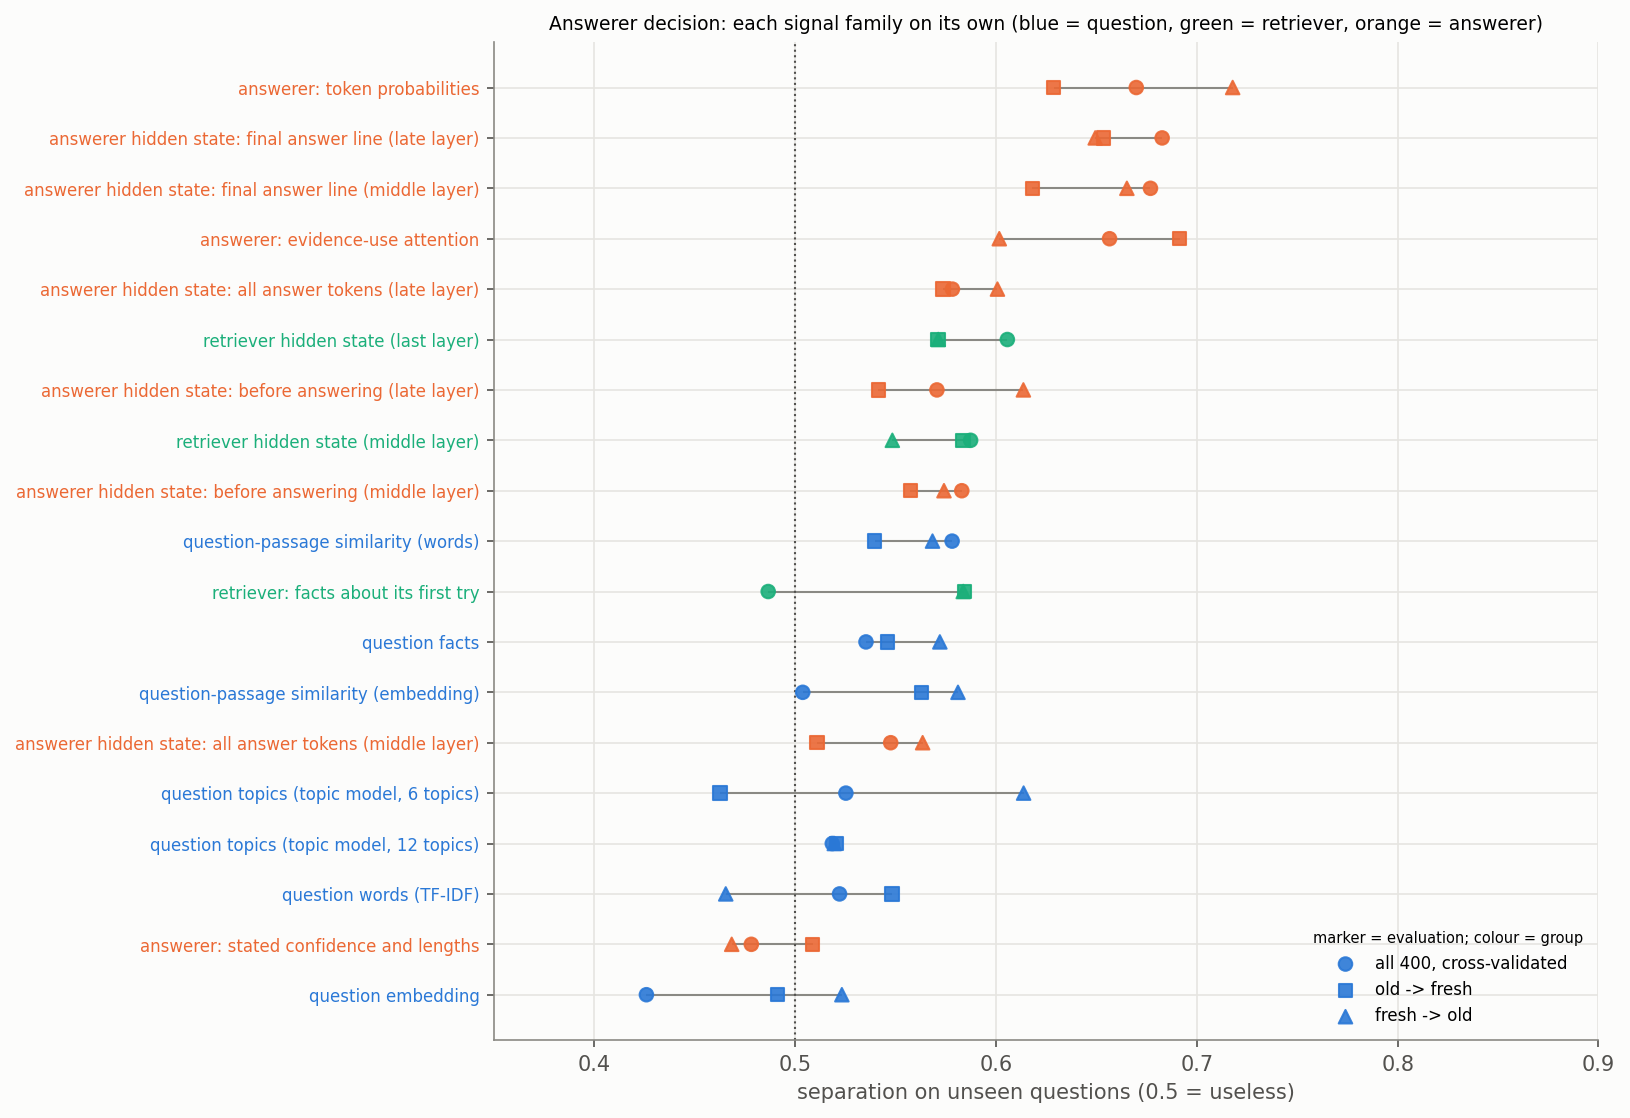

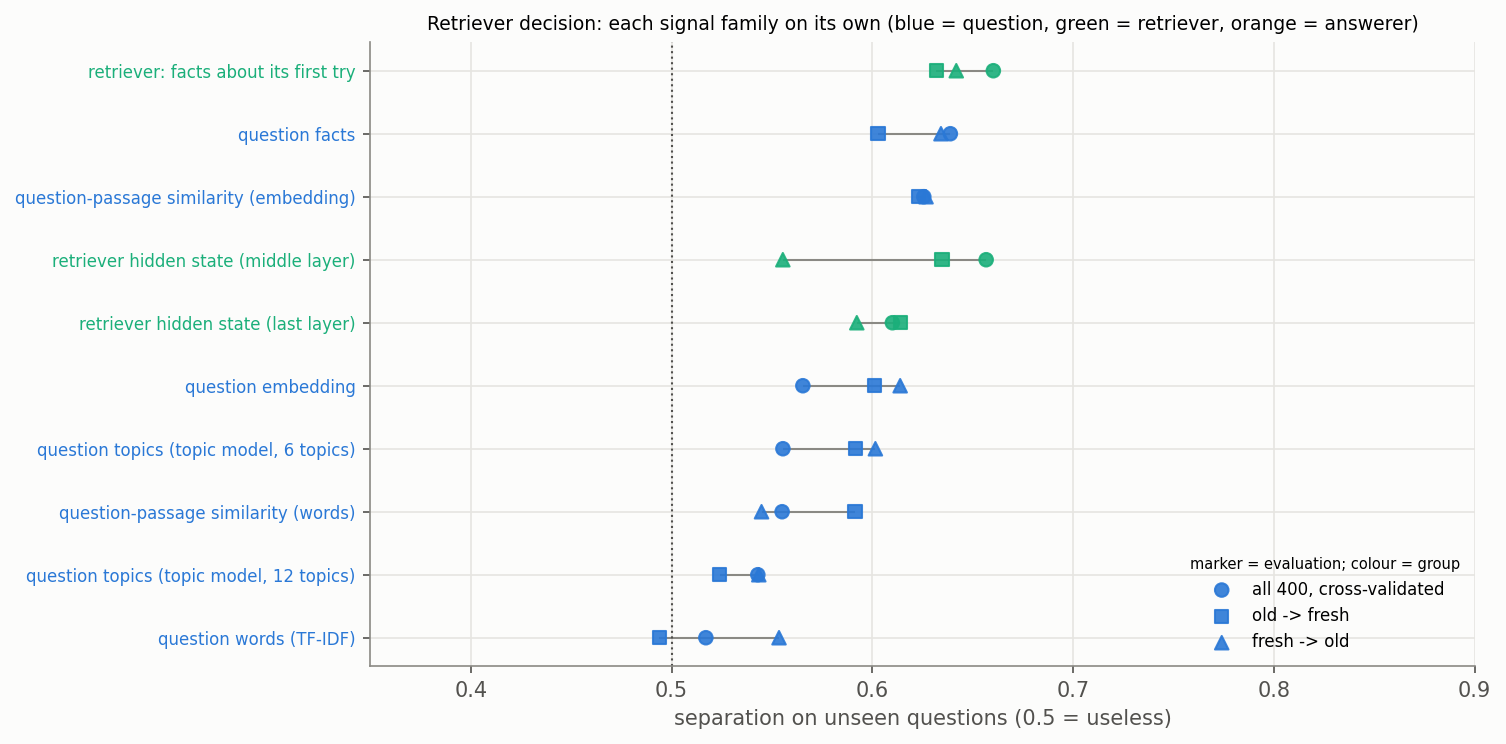

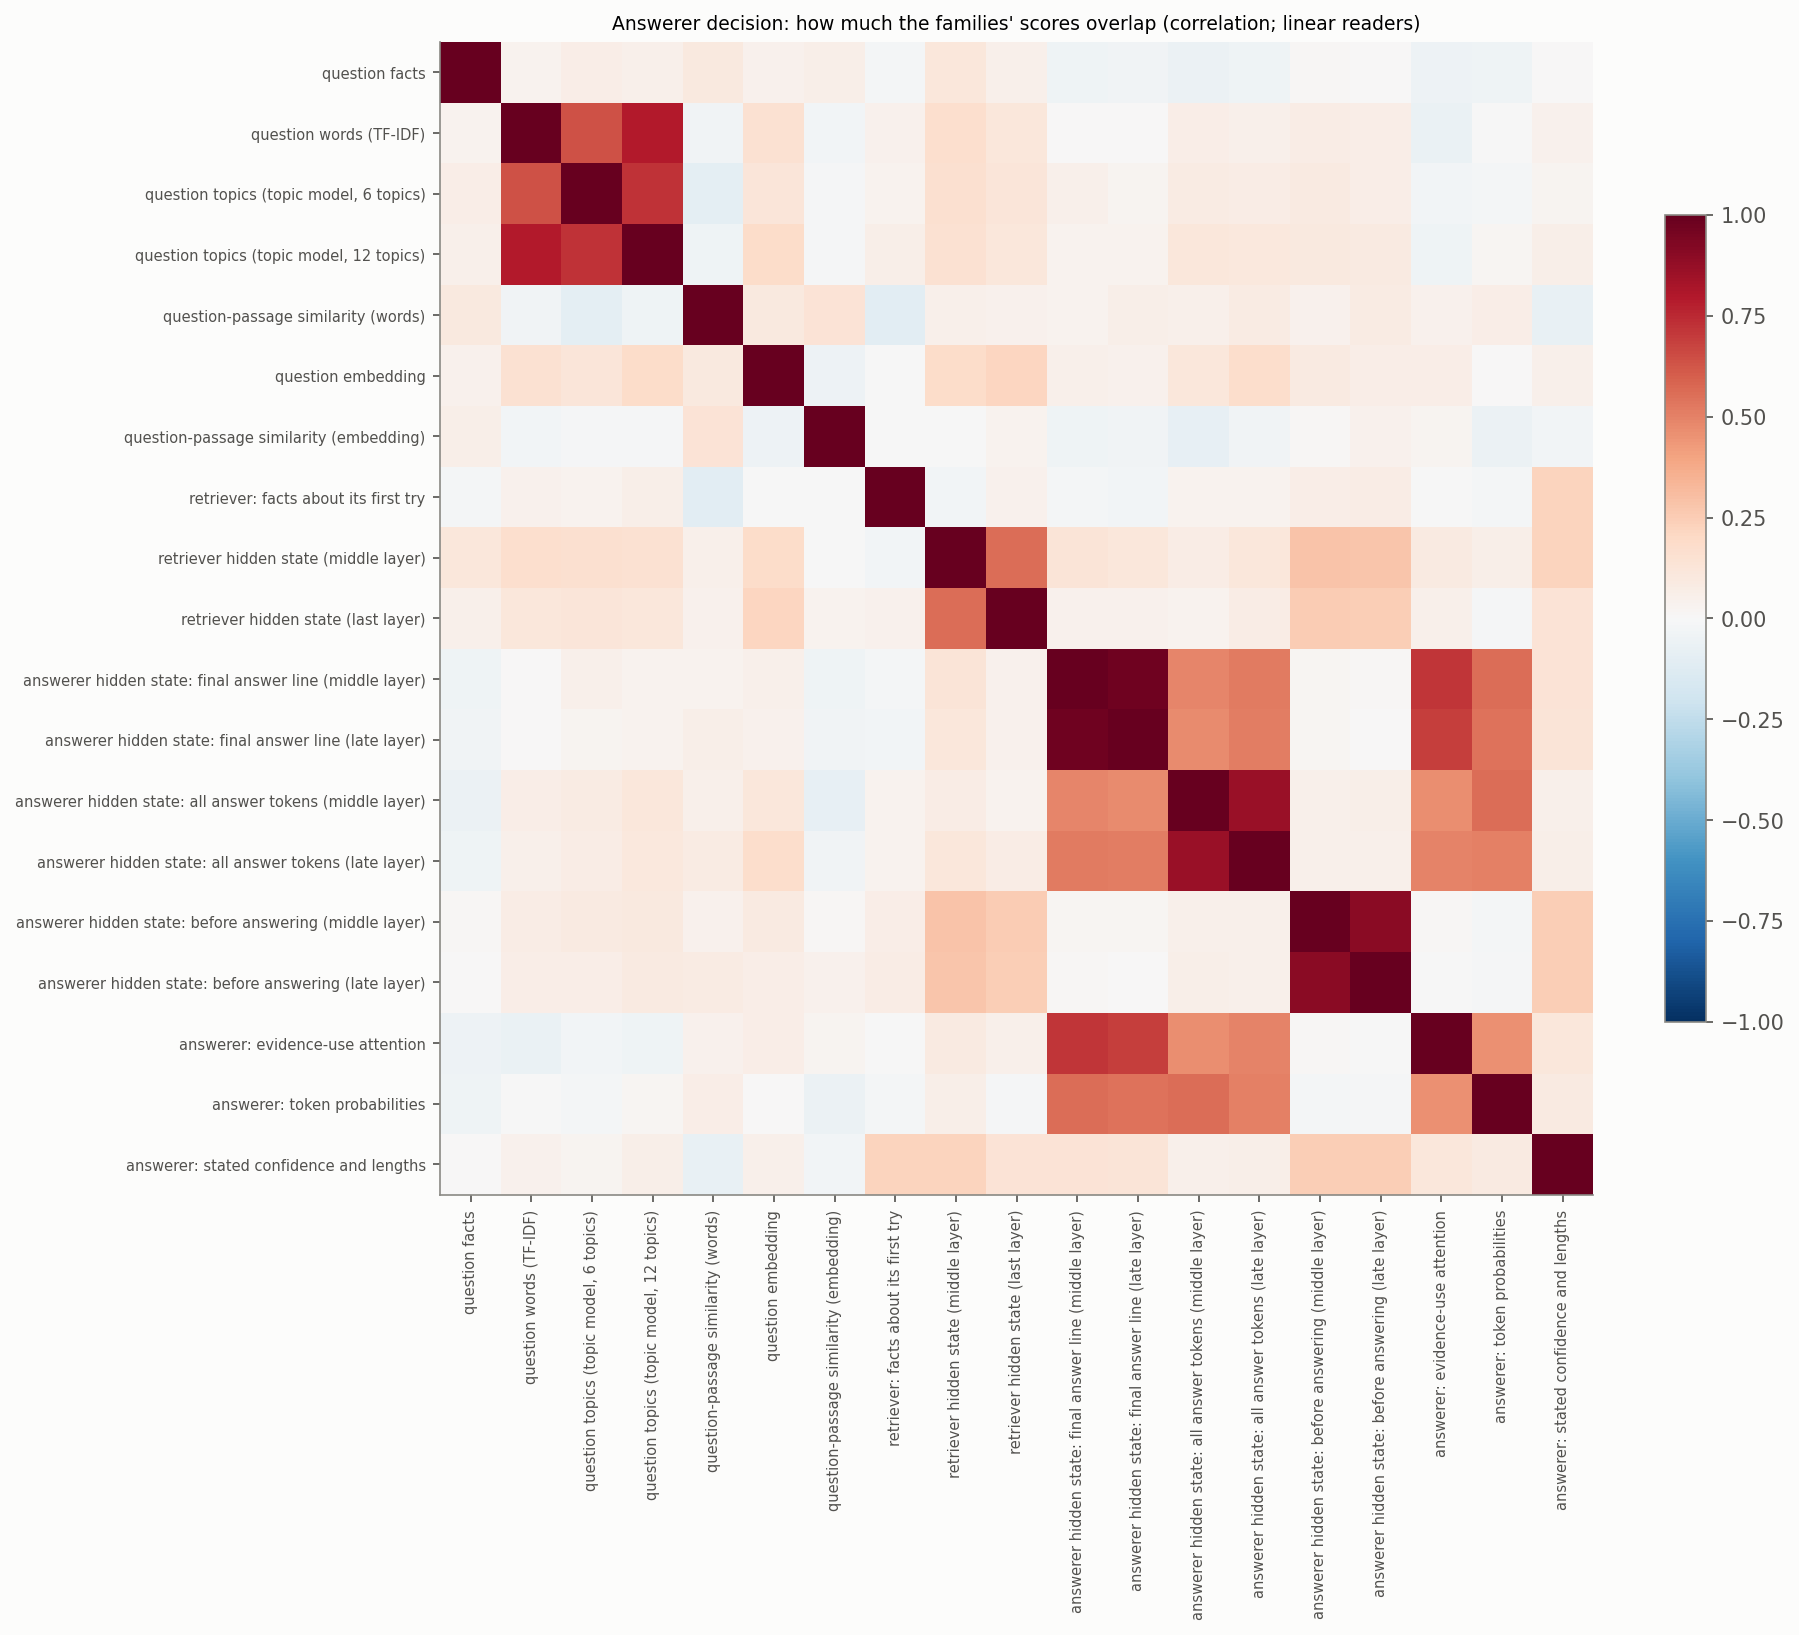

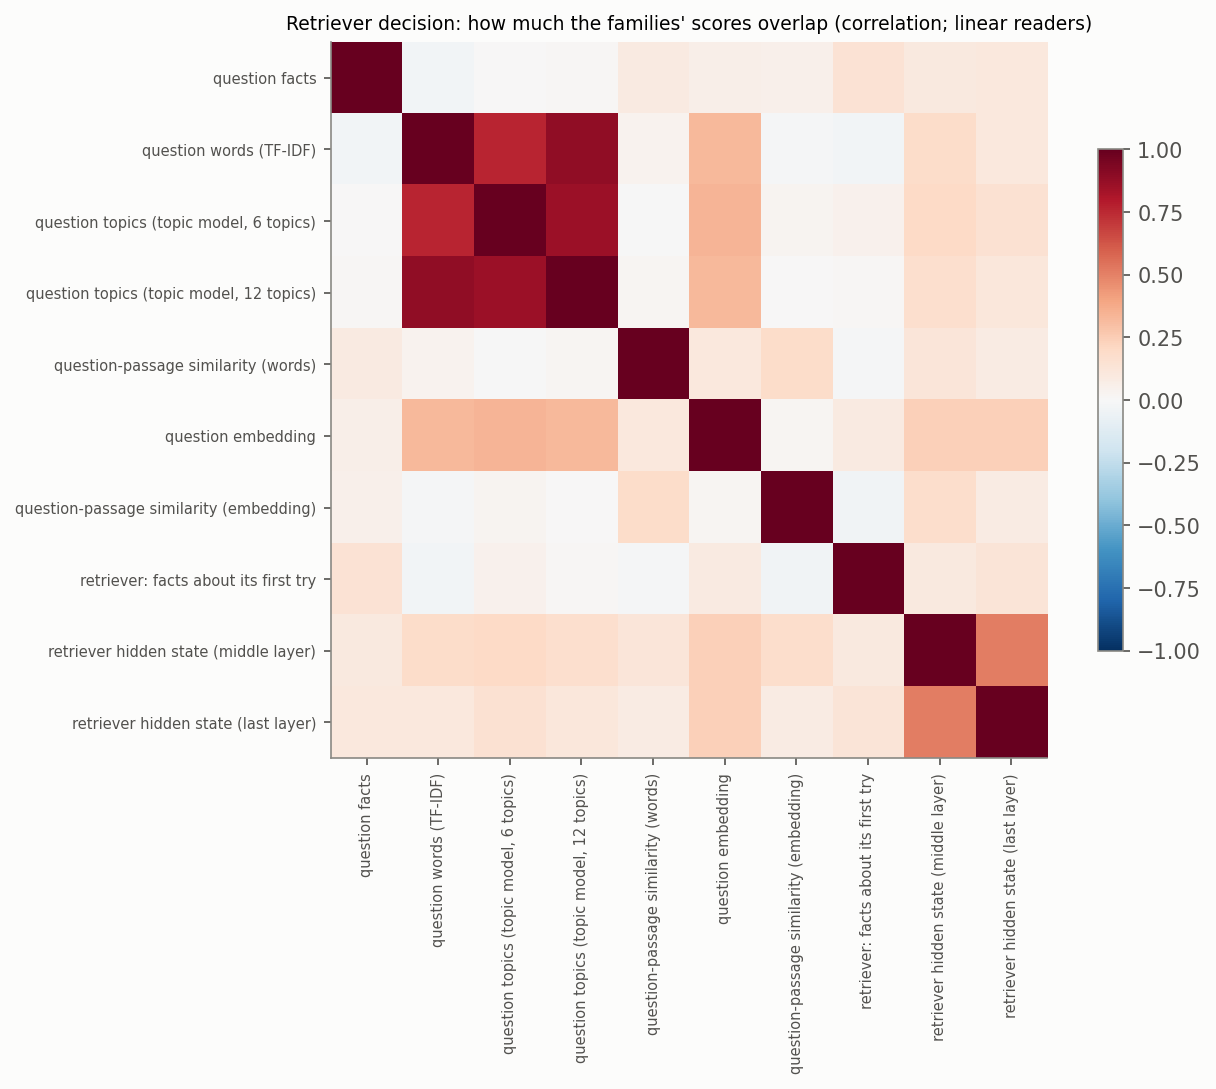

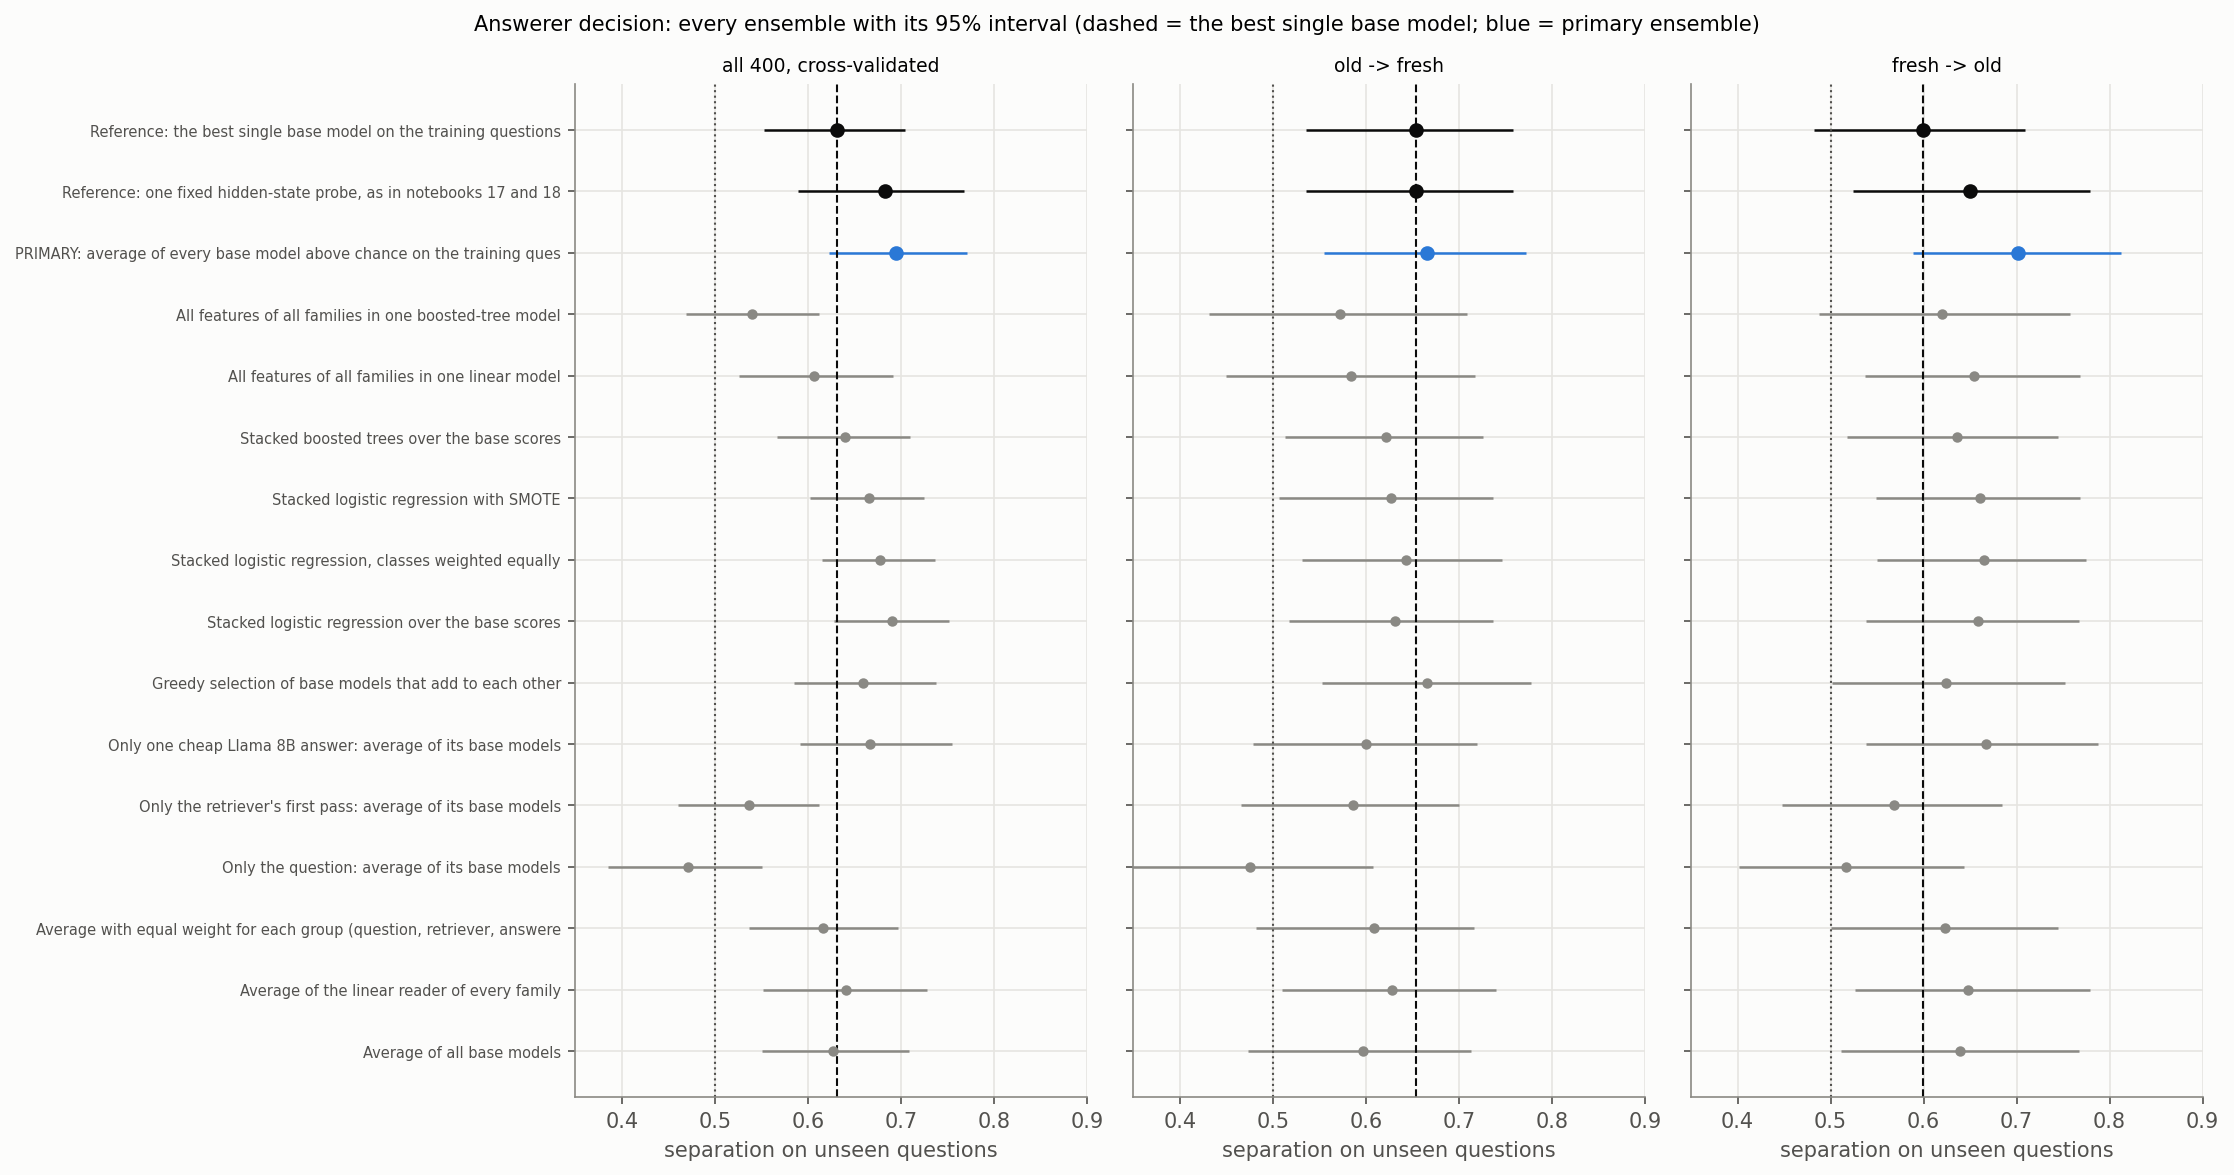

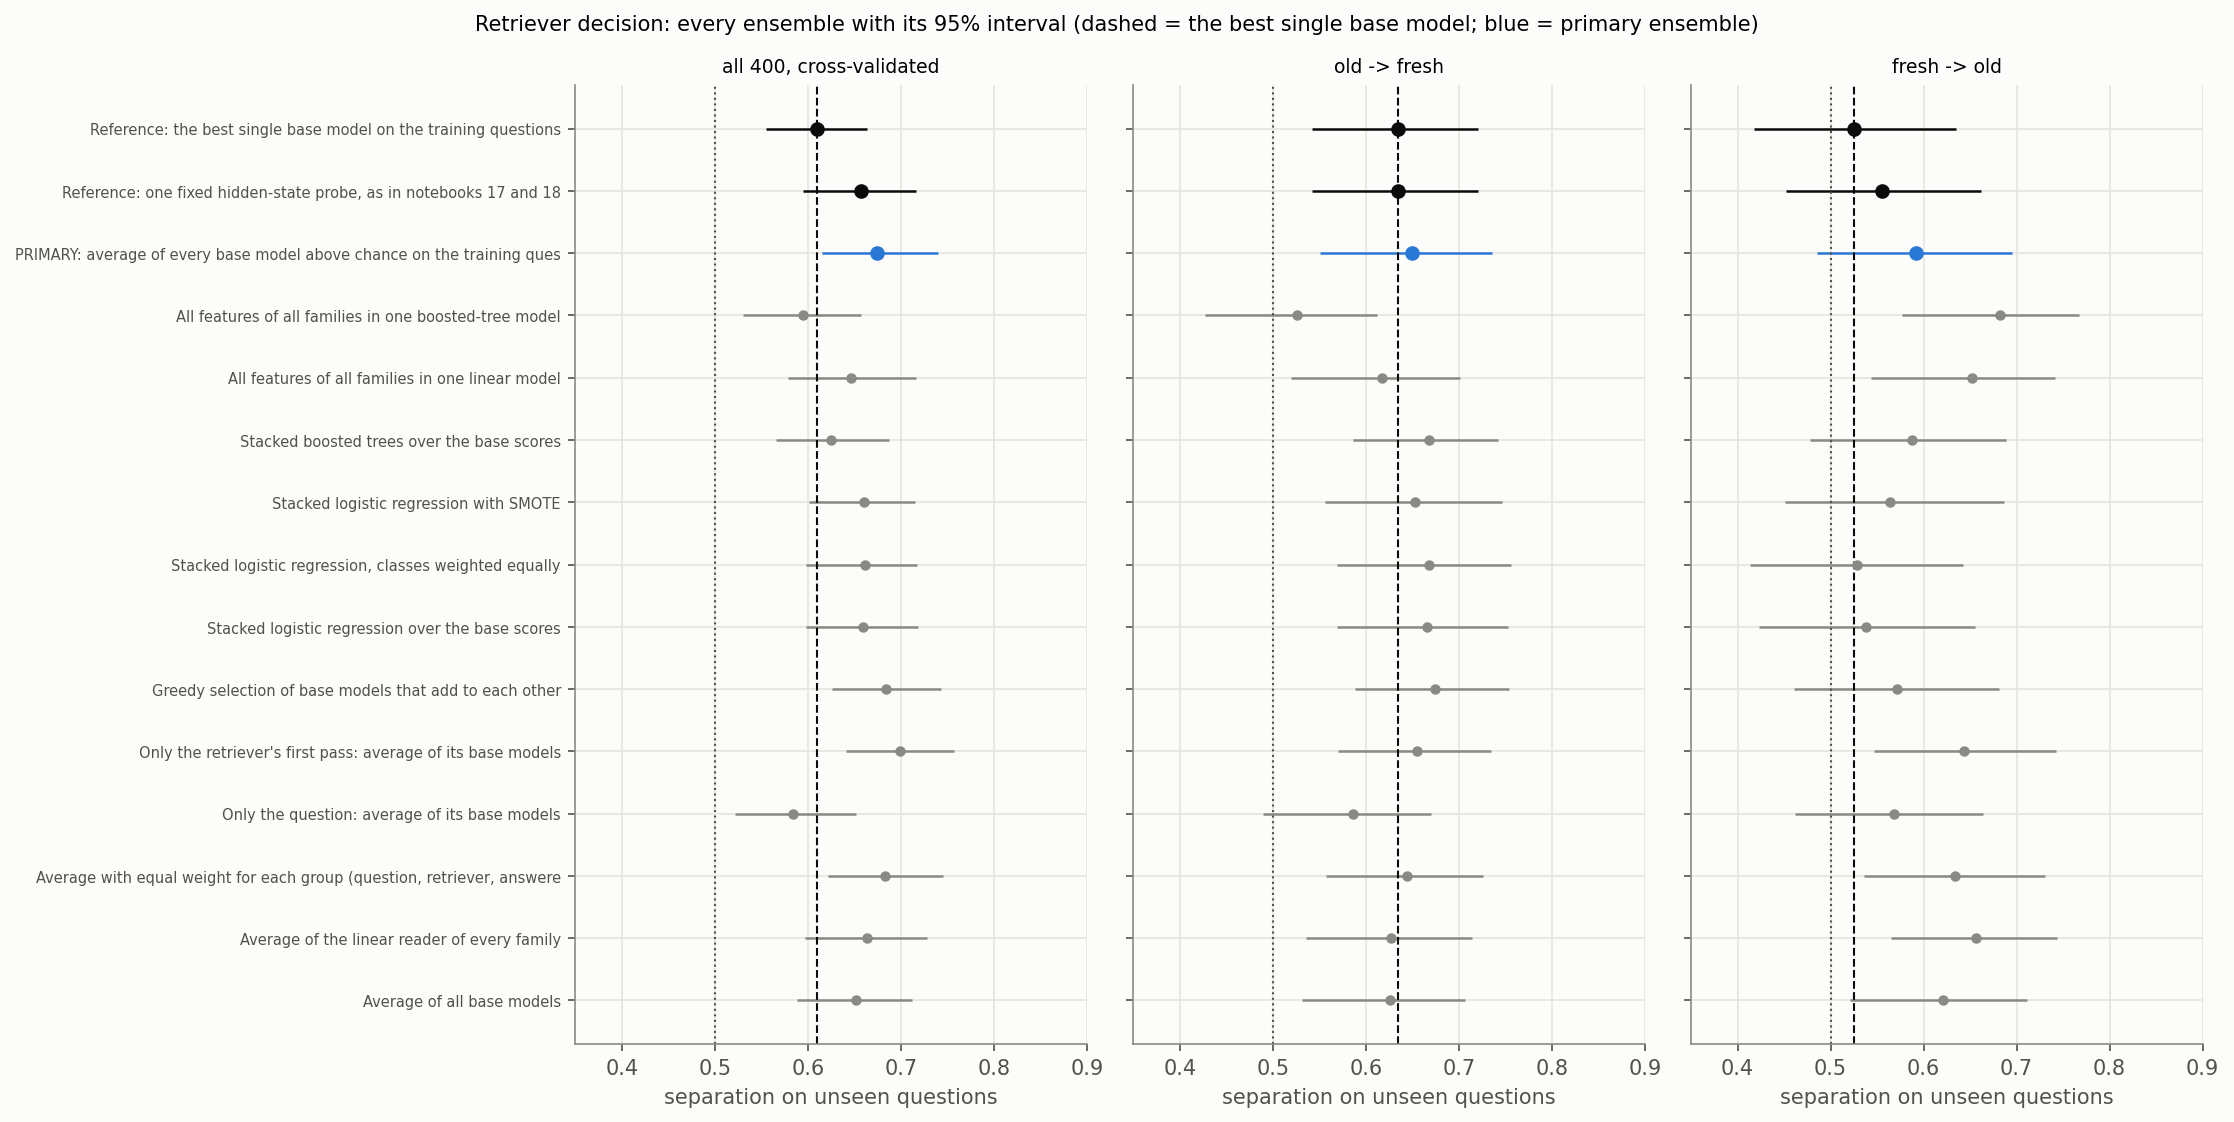

Excel workbook: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_2__question-reading-routers/20261007-233327_cpu_ensembles/results/set5f_ensembles.xlsx

ALL DONE in 26 min.
Saved to Drive.


In [5]:
cmd = [sys.executable, "-u", f"{CODE_DIR}/ensemble.py", "run", "--old_sweep", OLD_SWEEP, "--old_hidden", OLD_HIDDEN, "--old_data", OLD_DATA,
       "--fresh_run", FRESH_RUN, "--fresh_data", FRESH_DATA, "--run_dir", RUN_DIR, "--cv_repeats", str(CV_REPEATS)] + ([] if USE_EMBEDDING else ["--no_embedding"])
with open(f"{RUN_DIR}/logs/ensemble.log", "a") as log:
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        log.write(line)
        if "Warning" not in line and "warn" not in line:
            print(line, end="")
    p.wait()
assert p.returncode == 0, f"failed - see {RUN_DIR}/logs/ensemble.log"
from IPython.display import Image, Markdown, display
display(Markdown(open(f"{RUN_DIR}/results/summary.md").read()))
for f in sorted(glob.glob(f"{RUN_DIR}/results/charts/*.png")):
    display(Image(f))
json.dump({"session": SESSION, "seconds": round(time.time() - T_START)}, open(f"{RUN_DIR}/session.json", "w"), indent=1)
print("Excel workbook:", f"{RUN_DIR}/results/set5f_ensembles.xlsx")
print(f"\nALL DONE in {(time.time() - T_START) / 60:.0f} min.")
try:
    drive.flush_and_unmount()
    print("Saved to Drive.")
except Exception as e:
    print("Drive flush skipped:", e)